In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy.random as rd
import numpy as np

In [4]:
with open('data_description.txt') as filin:
  print(filin.read())

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [5]:
#importation et afficheage de la base de données
df=pd.read_csv('train.csv')
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [6]:
df.info()  #on a mis 1460 lignes et 81 colonnes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [8]:
#s'il contient des valeurs nulls

In [9]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [10]:
#nombre de colonne de type entier et textes
df.dtypes.value_counts()

,count
object,43
int64,35
float64,3


In [11]:
#la taille
df.shape

(1460, 81)

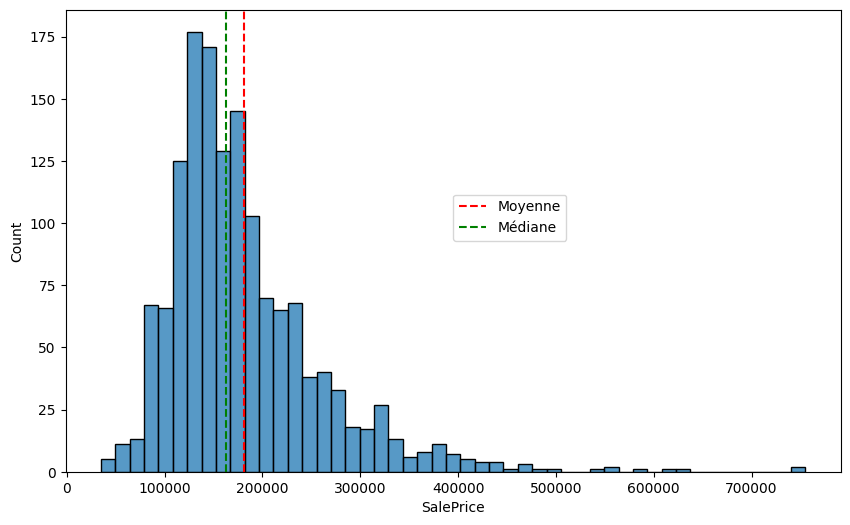

In [12]:
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df,x='SalePrice')
ax.axvline(df['SalePrice'].mean(),color='red',linestyle='--',label='Moyenne')
ax.axvline(df['SalePrice'].median(),color='green',linestyle='--',label='Médiane')
plt.legend(loc=(0.5,0.5))
plt.show()

In [13]:
moyenne=df['SalePrice'].mean().round(2)
moyenne
#la moyenne du Prix de vente

np.float64(180921.2)

In [14]:
#mediane
mediane=df['SalePrice'].median()
mediane

163000.0

In [15]:
#la moyenne est plus grande car tous les prix sont concentées vers la moyenne

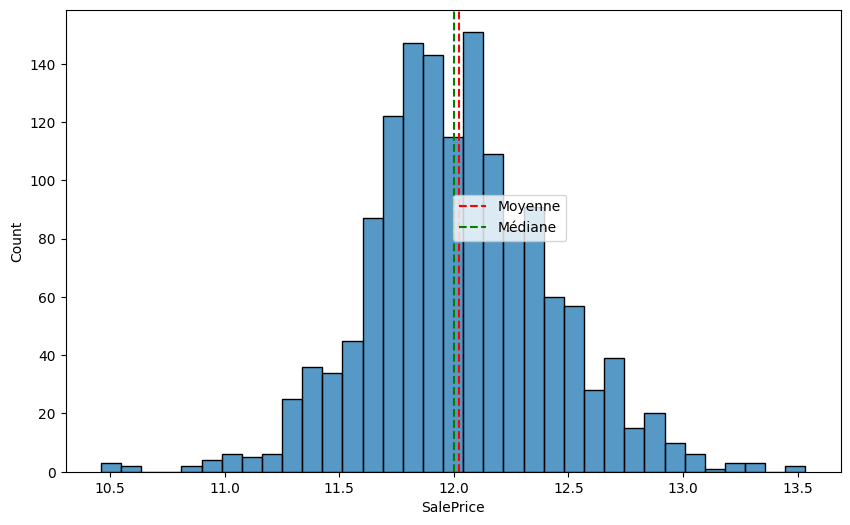

In [16]:
#son logarithme
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(data=df,x=np.log(df['SalePrice']))
ax.axvline(np.log(df['SalePrice']).mean(),color='red',linestyle='--',label='Moyenne')
ax.axvline(np.log(df['SalePrice']).median(),color='green',linestyle='--',label='Médiane')
plt.legend(loc=(0.5,0.5))
plt.show()

In [17]:
#les valeurs manquantes et la colonnes la plus touchées
percent=100*df.isnull().sum().sort_values(ascending=False)/len(df)
percent


,0
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
...,...
MoSold,0.000000
YrSold,0.000000
SaleType,0.000000
SaleCondition,0.000000


In [18]:
def missing_values(df):
  percent_value=percent=100*df.isnull().sum()/len(df)
  percent_value=percent_value[percent_value>0].sort_values()

  return percent_value


In [19]:
print(missing_values(df))

Electrical       0.068493
MasVnrArea       0.547945
BsmtCond         2.534247
BsmtFinType1     2.534247
BsmtQual         2.534247
BsmtExposure     2.602740
BsmtFinType2     2.602740
GarageType       5.547945
GarageQual       5.547945
GarageFinish     5.547945
GarageCond       5.547945
GarageYrBlt      5.547945
LotFrontage     17.739726
FireplaceQu     47.260274
MasVnrType      59.726027
Fence           80.753425
Alley           93.767123
MiscFeature     96.301370
PoolQC          99.520548
dtype: float64


In [20]:
df.corr(numeric_only=True)['SalePrice'].sort_values()

,SalePrice
KitchenAbvGr,-0.135907
EnclosedPorch,-0.128578
MSSubClass,-0.084284
OverallCond,-0.077856
YrSold,-0.028923
LowQualFinSF,-0.025606
Id,-0.021917
MiscVal,-0.021190
BsmtHalfBath,-0.016844
BsmtFinSF2,-0.011378


In [21]:
#SalePrice, overall et GrlivArea sont très corrélé a SalePrice

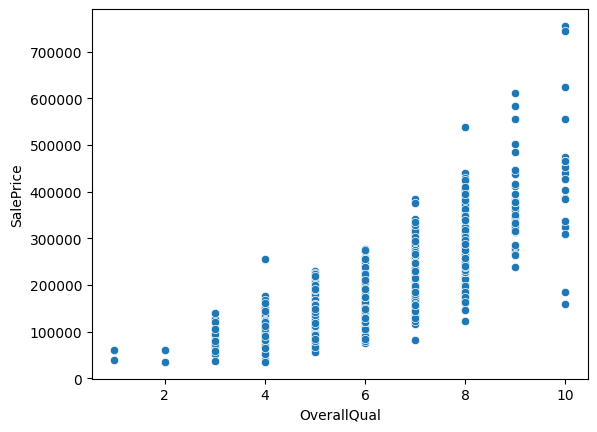

In [22]:
#histogram de salePrice et overall
''' plus la qualité de surface est grande plus le prix augmente '''

sns.scatterplot(data=df,x='OverallQual',y='SalePrice')
plt.show()

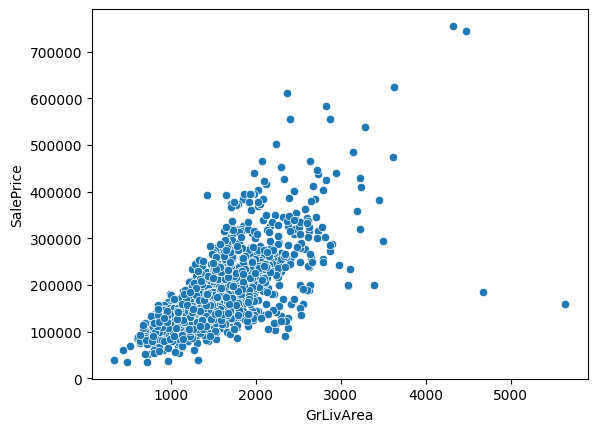

In [23]:
#Nuage de points de salePrice avec GrliveArea
sns.scatterplot(data=df,x='GrLivArea',y='SalePrice')
plt.show()

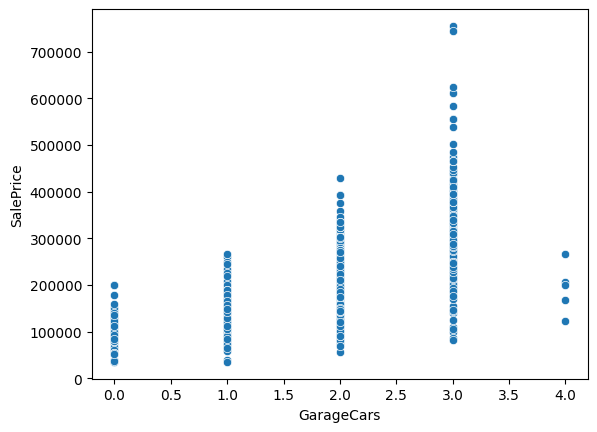

In [24]:
#Nuage de points de GarageCars et salePrice
sns.scatterplot(data=df,x='GarageCars',y='SalePrice')
plt.show()

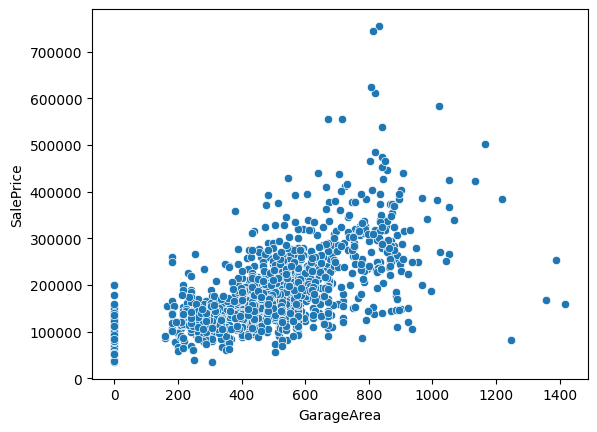

In [25]:
#Nuage entre GarageArea et saleprice
sns.scatterplot(data=df,x='GarageArea',y='SalePrice')
plt.show()

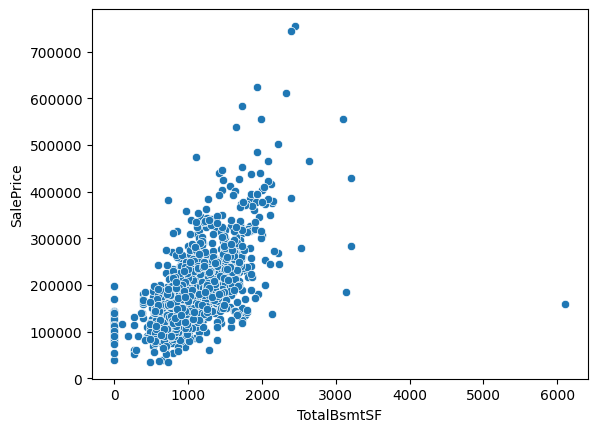

In [26]:
#Nuage entre totalBsmf et saleprice
sns.scatterplot(data=df,x='TotalBsmtSF',y='SalePrice')
plt.show()

In [27]:
df[(df['OverallQual']>8)&(df['SalePrice']<200000)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
523,524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,...,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,...,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


In [28]:
df[(df['GrLivArea']>4000)&(df['SalePrice']<200000)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
523,524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,...,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,...,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


In [29]:
df[(df['GarageCars']>3)&(df['SalePrice']<200000)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1190,1191,190,RL,NaN,32463,Pave,NaN,Reg,Low,AllPub,...,0,NaN,NaN,NaN,0,3,2007,WD,Normal,168000
1340,1341,20,RL,70.0,8294,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,6,2007,WD,Normal,123000


In [30]:
index_delete=df[(df['GrLivArea']>4000)&(df['SalePrice']<200000)].index
df=df.drop(index_delete)

In [31]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


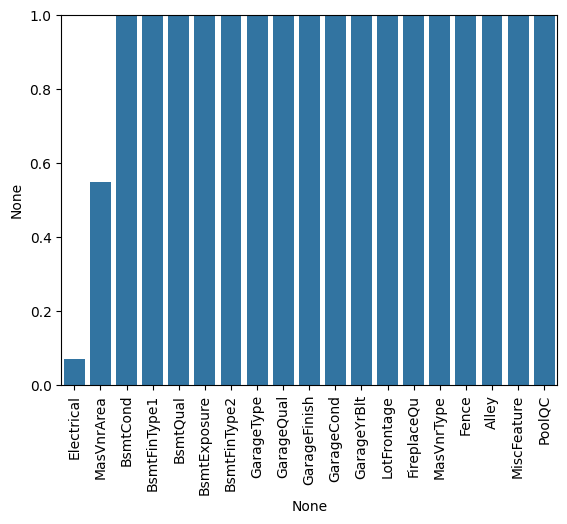

In [32]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.show()

In [33]:
pourcentage_manquants[pourcentage_manquants<0.1]
df[df['Electrical'].isnull()]
df=df.dropna(subset=['Electrical'], axis=0)
#


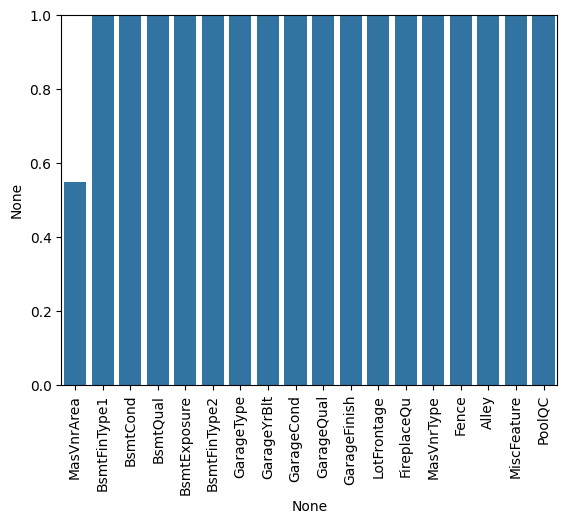

In [34]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.show()

In [35]:
df[df['MasVnrArea'].isnull()]
df['MasVnrArea']=df['MasVnrArea'].fillna(0)

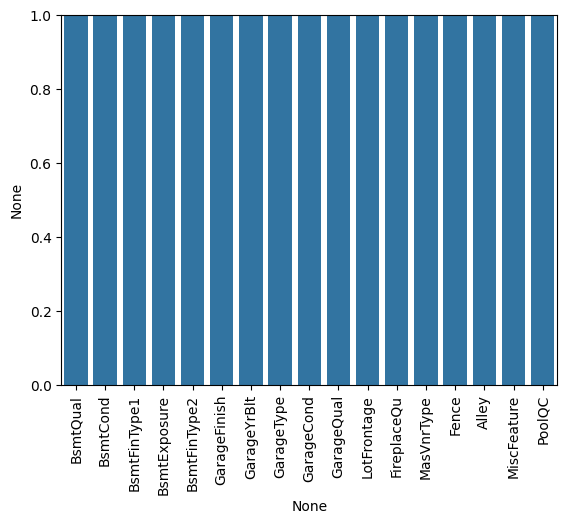

In [36]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.show()

In [37]:
liste=['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']
for i in liste:
  df[i]=df[i].fillna('None')

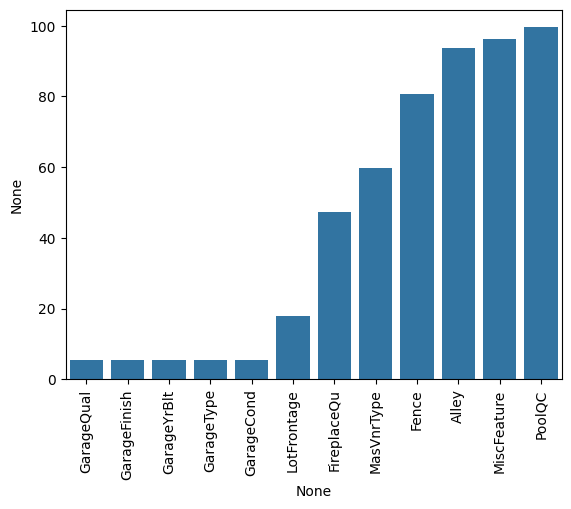

In [38]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.show()

In [39]:
liste1=['GarageType','GarageFinish','GarageQual','GarageCond']
for i in liste1:
  df[i]=df[i].fillna('None')

In [40]:
df[liste1]=df[liste1].fillna('None')

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1457 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1457 non-null   int64  
 1   MSSubClass     1457 non-null   int64  
 2   MSZoning       1457 non-null   object 
 3   LotFrontage    1198 non-null   float64
 4   LotArea        1457 non-null   int64  
 5   Street         1457 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1457 non-null   object 
 8   LandContour    1457 non-null   object 
 9   Utilities      1457 non-null   object 
 10  LotConfig      1457 non-null   object 
 11  LandSlope      1457 non-null   object 
 12  Neighborhood   1457 non-null   object 
 13  Condition1     1457 non-null   object 
 14  Condition2     1457 non-null   object 
 15  BldgType       1457 non-null   object 
 16  HouseStyle     1457 non-null   object 
 17  OverallQual    1457 non-null   int64  
 18  OverallCond  

In [42]:
df['GarageYrBlt']=df['GarageYrBlt'].fillna(df['YearBuilt'])

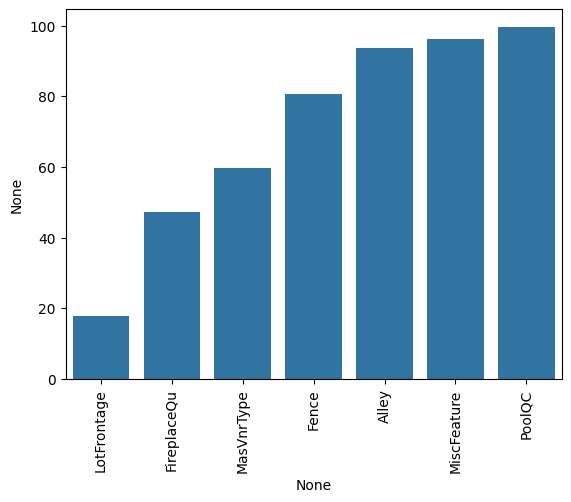

In [43]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)

plt.show()

In [44]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [45]:
df['MiscFeature']=df['MiscFeature'].fillna('None')

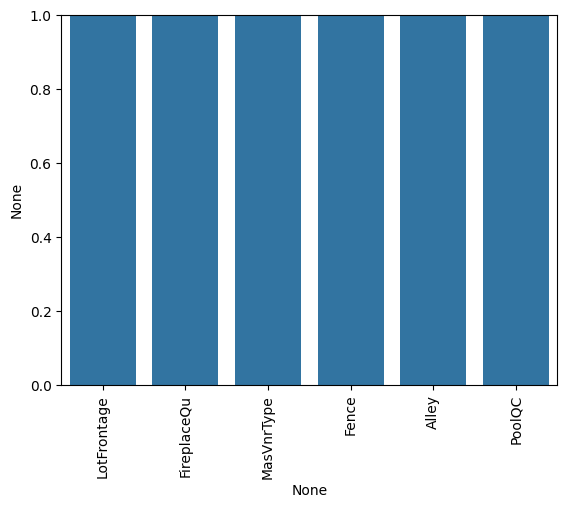

In [46]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.show()

In [47]:

df['FireplaceQu']=df['FireplaceQu'].fillna('None')
df['MasVnrType']=df['MasVnrType'].fillna('None')
df['LotFrontage']=df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

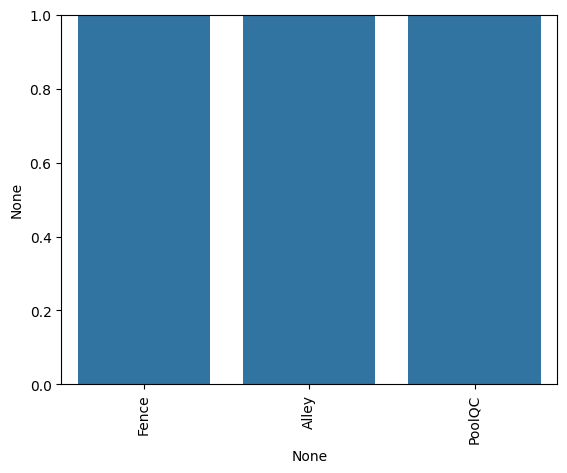

In [48]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.show()

In [49]:
liste=['Fence','Alley','PoolQC']
for i in liste:
  df[i]=df[i].fillna('None')

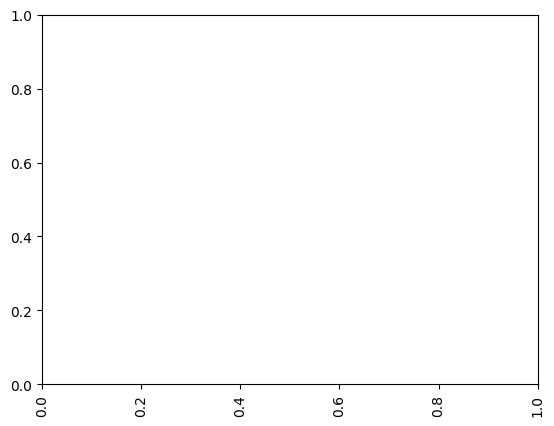

In [50]:
pourcentage_manquants=missing_values(df)
pourcentage_manquants
sns.barplot(x=pourcentage_manquants.index,y=pourcentage_manquants)
plt.xticks(rotation=90)
plt.ylim(0,1)
plt.show()

In [51]:
df.drop('Id',axis=1)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,Inside,...,0,None,None,None,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,...,0,None,None,None,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,Inside,...,0,None,None,None,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,Corner,...,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,FR2,...,0,None,None,None,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,None,Reg,Lvl,AllPub,Inside,...,0,None,None,None,0,8,2007,WD,Normal,175000
1456,20,RL,85.0,13175,Pave,None,Reg,Lvl,AllPub,Inside,...,0,None,MnPrv,None,0,2,2010,WD,Normal,210000
1457,70,RL,66.0,9042,Pave,None,Reg,Lvl,AllPub,Inside,...,0,None,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,20,RL,68.0,9717,Pave,None,Reg,Lvl,AllPub,Inside,...,0,None,None,None,0,4,2010,WD,Normal,142125


In [52]:
df['MSSubClass']=df['MSSubClass'].apply(str)

In [53]:
df.select_dtypes(include='object')

,MSSubClass,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,60,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
1,20,RL,Pave,None,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
2,60,RL,Pave,None,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
3,70,RL,Pave,None,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,Detchd,Unf,TA,TA,Y,None,None,None,WD,Abnorml
4,60,RL,Pave,None,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
1456,20,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,Attchd,Unf,TA,TA,Y,None,MnPrv,None,WD,Normal
1457,70,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,Attchd,RFn,TA,TA,Y,None,GdPrv,Shed,WD,Normal
1458,20,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,Attchd,Unf,TA,TA,Y,None,None,None,WD,Normal


In [54]:
donnee_string=df.select_dtypes(include='object')
donnee_string


,MSSubClass,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,60,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
1,20,RL,Pave,None,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
2,60,RL,Pave,None,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
3,70,RL,Pave,None,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,Detchd,Unf,TA,TA,Y,None,None,None,WD,Abnorml
4,60,RL,Pave,None,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,Attchd,RFn,TA,TA,Y,None,None,None,WD,Normal
1456,20,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,Attchd,Unf,TA,TA,Y,None,MnPrv,None,WD,Normal
1457,70,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,Attchd,RFn,TA,TA,Y,None,GdPrv,Shed,WD,Normal
1458,20,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,Attchd,Unf,TA,TA,Y,None,None,None,WD,Normal


In [55]:
donne_numerique=df.select_dtypes(exclude='object')
donne_numerique

,Id,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,1,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
1,2,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
2,3,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
3,4,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
4,5,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,62.0,7917,6,5,1999,2000,0.0,0,0,...,0,40,0,0,0,0,0,8,2007,175000
1456,1457,85.0,13175,6,6,1978,1988,119.0,790,163,...,349,0,0,0,0,0,0,2,2010,210000
1457,1458,66.0,9042,7,9,1941,2006,0.0,275,0,...,0,60,0,0,0,0,2500,5,2010,266500
1458,1459,68.0,9717,5,6,1950,1996,0.0,49,1029,...,366,0,112,0,0,0,0,4,2010,142125


In [56]:
df_dummies=pd.get_dummies(donnee_string,drop_first=True,dtype=int)
df_final=pd.concat([donne_numerique.drop(columns='SalePrice'),df_dummies],axis=1)
df_final

,Id,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,0,0,0,1,0,0,0,1,0
1,2,80.0,9600,6,8,1976,1976,0.0,978,0,...,0,0,0,0,1,0,0,0,1,0
2,3,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,0,0,0,1,0,0,0,1,0
3,4,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,0,0,0,1,0,0,0,0,0
4,5,84.0,14260,8,5,2000,2000,350.0,655,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,62.0,7917,6,5,1999,2000,0.0,0,0,...,0,0,0,0,1,0,0,0,1,0
1456,1457,85.0,13175,6,6,1978,1988,119.0,790,163,...,0,0,0,0,1,0,0,0,1,0
1457,1458,66.0,9042,7,9,1941,2006,0.0,275,0,...,0,0,0,0,1,0,0,0,1,0
1458,1459,68.0,9717,5,6,1950,1996,0.0,49,1029,...,0,0,0,0,1,0,0,0,1,0


In [57]:
df.duplicated().sum()

np.int64(0)

In [58]:
plt.figure(figsize=(10,8),dpi=200)
##sns.heatmap(df.corr(numeric_only=True),annot=True)
df.corr(numeric_only=True)['GarageArea'].sort_values()
#sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

<Figure size 2000x1600 with 0 Axes>

In [59]:
df.corr(numeric_only=True)['SalePrice'].sort_values()

,SalePrice
KitchenAbvGr,-0.135974
EnclosedPorch,-0.128694
OverallCond,-0.078016
YrSold,-0.028866
LowQualFinSF,-0.025639
Id,-0.021512
MiscVal,-0.021214
BsmtHalfBath,-0.016909
BsmtFinSF2,-0.011456
3SsnPorch,0.044555


In [60]:
df=df.drop('GarageCars',axis=1)

In [61]:
df.shape

(1457, 80)

In [62]:
df['TotalBath']=df['FullBath']+0.5*df['HalfBath']+df['BsmtFullBath']+0.5*df['BsmtHalfBath']
df_final['TotalBath']=df['TotalBath']

In [63]:
df.corr(numeric_only=True)['SalePrice'].sort_values()

,SalePrice
KitchenAbvGr,-0.135974
EnclosedPorch,-0.128694
OverallCond,-0.078016
YrSold,-0.028866
LowQualFinSF,-0.025639
Id,-0.021512
MiscVal,-0.021214
BsmtHalfBath,-0.016909
BsmtFinSF2,-0.011456
3SsnPorch,0.044555


In [64]:
#La variable la plus correlé  avec la cible est OverallQual

In [65]:
df_final=df_final.drop(['FullBath','HalfBath','BsmtFullBath','BsmtHalfBath','GarageCars'],axis=1)

In [66]:
df.shape

(1457, 81)

In [67]:
df_final=df_final.drop('Id',axis=1)

In [68]:
df_final

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,TotalBath
0,65.0,8450,7,5,2003,2003,196.0,706,0,150,...,0,0,0,1,0,0,0,1,0,3.5
1,80.0,9600,6,8,1976,1976,0.0,978,0,284,...,0,0,0,1,0,0,0,1,0,2.5
2,68.0,11250,7,5,2001,2002,162.0,486,0,434,...,0,0,0,1,0,0,0,1,0,3.5
3,60.0,9550,7,5,1915,1970,0.0,216,0,540,...,0,0,0,1,0,0,0,0,0,2.0
4,84.0,14260,8,5,2000,2000,350.0,655,0,490,...,0,0,0,1,0,0,0,1,0,3.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,62.0,7917,6,5,1999,2000,0.0,0,0,953,...,0,0,0,1,0,0,0,1,0,2.5
1456,85.0,13175,6,6,1978,1988,119.0,790,163,589,...,0,0,0,1,0,0,0,1,0,3.0
1457,66.0,9042,7,9,1941,2006,0.0,275,0,877,...,0,0,0,1,0,0,0,1,0,2.0
1458,68.0,9717,5,6,1950,1996,0.0,49,1029,0,...,0,0,0,1,0,0,0,1,0,2.0


In [69]:
df.shape

(1457, 81)

In [70]:
'GarageCars' in df.columns

False

In [71]:
'SalePrice' in df_dummies

False

In [72]:
#importation des bibliothèques
rd.seed(42)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error,mean_absolute_percentage_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_val_score

In [73]:
#regression lineaire simple avec Overallqual
X=df_final[['OverallQual']]
y=df['SalePrice']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [74]:
model_simple=LinearRegression()
model_simple.fit(X_train,y_train)

LinearRegression()

In [75]:
y_pred_simple=model_simple.predict(X_test)


In [76]:
model_simple.coef_

array([45748.05397525])

In [77]:
#le coeficient  beta 1 est d'environ 45748,05 et donc pour une augmentation de overall le prix augmentera de 45758.03

In [78]:
model_simple.intercept_

np.float64(-98498.68575141931)

In [79]:
#Ici Betta_0 est egale a environ -98498,69 c'est donc le prix de base quand overallqual=0

In [80]:
MAE_simple=mean_absolute_error(y_test,y_pred_simple)
MAE_simple

32245.51380771776

In [81]:
RMSE_simple=np.sqrt(mean_squared_error(y_test,y_pred_simple))
RMSE_simple

np.float64(44016.55507287185)

In [82]:
r2_simple=r2_score(y_test,y_pred_simple)
r2_simple

0.6877455484708943

In [83]:
MAPE=mean_absolute_percentage_error(y_test,y_pred_simple)
MAPE

0.20050342465549342

In [84]:
residus=y_test-y_pred_simple
residus

,SalePrice
497,-37737.692075
1263,4510.361900
411,14758.415875
1048,-15241.584125
1035,-493.530150
...,...
477,66766.199974
675,-27489.638100
1300,3262.307925
650,-15787.692075


Text(0, 0.5, 'Résidu (y_test - y_pred)')

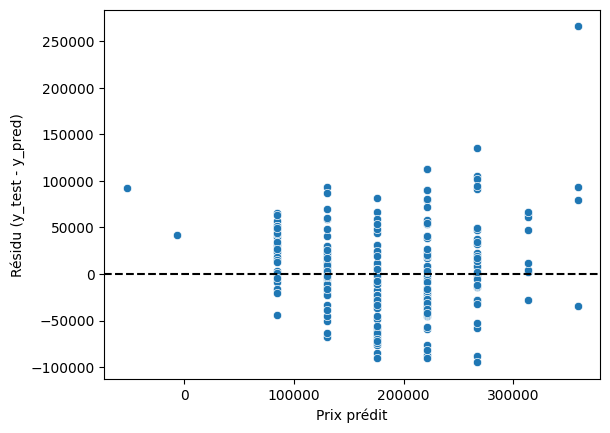

In [85]:
sns.scatterplot(x=y_pred_simple, y=residus)
plt.axhline(0, color='black', linestyle='--')   # la ligne du zéro
plt.xlabel('Prix prédit'); plt.ylabel('Résidu (y_test - y_pred)')

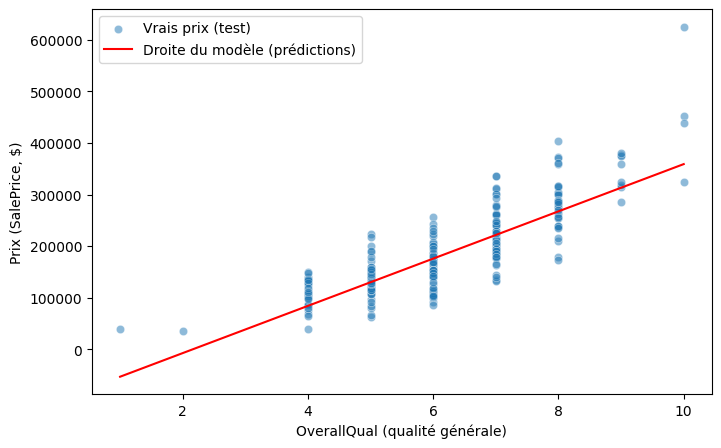

In [86]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_test['OverallQual'], y=y_test, alpha=0.5, label='Vrais prix (test)')

sns.lineplot(x=X_test['OverallQual'], y=y_pred_simple, color='red',
             errorbar=None, label='Droite du modèle (prédictions)')
plt.xlabel('OverallQual (qualité générale)')
plt.ylabel('Prix (SalePrice, $)')
plt.legend()
plt.show()

In [87]:
#Regression avec les deux variables les plus correlés
X=df_final[['OverallQual','GrLivArea']]
y=df['SalePrice']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [88]:
modele_deux=LinearRegression()
modele_deux.fit(X_train,y_train)

LinearRegression()

In [89]:
y_pred_deux=modele_deux.predict(X_test)

In [90]:
modele_deux.coef_

array([31514.81924826,    68.05960219])

In [91]:
#si la qualité augmente d'une unite et toute chose egale par ailleurs alors le prix augmente d'environ 31514,82
#si le grliv augmente d'une unité toute chose par ailleurs alors le saleprice augmente d'environ 69

In [92]:
MAE_deux=mean_absolute_error(y_test,y_pred_deux)
MAE_deux

28761.664279887824

In [93]:
RMSE_deux=np.sqrt(mean_squared_error(y_test,y_pred_deux))
RMSE_deux

np.float64(38455.52062221046)

In [94]:
r2_deux=r2_score(y_test,y_pred_deux)
r2_deux

0.7616616493754282

In [95]:
#l'ajout d'une variable ne baisse pas le coefficient de determination etnat que Grliv est fortement correlé a Saleprice
#on observe une amelioration du score

In [96]:
MAPE_deux=mean_absolute_percentage_error(y_test,y_pred_deux)
MAPE_deux

0.18643655494961775

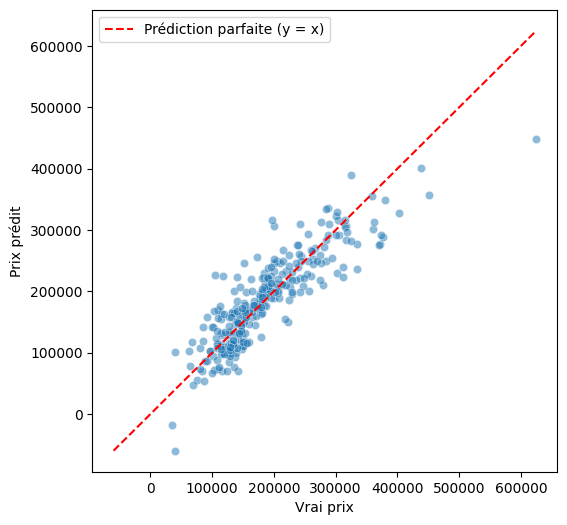

In [97]:
cols = ['OverallQual', 'GrLivArea']
modele_deux = LinearRegression()
modele_deux.fit(X_train[cols], y_train)
y_pred_deux = modele_deux.predict(X_test[cols])

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred_deux, alpha=0.5)
lim = [min(y_test.min(), y_pred_deux.min()), max(y_test.max(), y_pred_deux.max())]
sns.lineplot(x=lim, y=lim, color='red', linestyle='--', label='Prédiction parfaite (y = x)')
plt.xlabel('Vrai prix')
plt.ylabel('Prix prédit')
plt.legend()
plt.show()

In [98]:
X=df_final
y=df['SalePrice']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [99]:
scale=StandardScaler()
scale.fit(X_train)
X_train_scaled=scale.transform(X_train)
X_test_scaled=scale.transform(X_test)


In [100]:
model=LinearRegression()
model.fit(X_train_scaled,y_train)
y_pred_OLS=model.predict(X_test_scaled)

In [101]:
MSE=mean_squared_error(y_test,y_pred_OLS)
RMSE=np.sqrt(MSE)
R2=r2_score(y_test,y_pred_OLS)

In [102]:
RMSE

np.float64(27209.92164151951)

In [103]:
R2

0.8806750884510877

In [104]:
MSE_train=mean_squared_error(y_train,model.predict(X_train_scaled))
RMSE_train=np.sqrt(MSE_train)
R2_train=r2_score(y_train,model.predict(X_train_scaled))

In [105]:
RMSE_train

np.float64(18822.447192420266)

In [106]:
R2_train

0.944157034876983

In [107]:
#ELASTICNET
from sklearn.linear_model import ElasticNet



In [108]:
def modelisation(alpha):

  return make_pipeline(StandardScaler(),
                       ElasticNet(alpha=alpha,l1_ratio=0.5,max_iter=10000)
                       )

In [109]:
pipe=modelisation(1)
pipe.fit(X_train,y_train)
y_pred=pipe.predict(X_test)
MSE=mean_squared_error(y_test,y_pred)

In [110]:
r2_elastic=round(r2_score(y_test,y_pred),2)
r2_elastic

0.9

In [111]:
RMSE=np.sqrt(MSE)
RMSE

np.float64(24689.179183519907)

In [112]:
r2_train_elastic=round(r2_score(y_train,pipe.predict(X_train)),2)
r2_train_elastic

0.91

In [113]:
RMSE_train_elastic=np.sqrt(mean_squared_error(y_train,pipe.predict(X_train)))

In [114]:
RMSE_train_elastic

np.float64(23324.030362760273)

In [115]:
#bonne amélioration avec ElasticNet par rapport à LinearRegression

In [116]:
#on cherche le meilleur réglage avec GridSearchCV
from sklearn.model_selection import GridSearchCV
params = {
    'elasticnet__alpha': [0.01, 0.03, 0.1, 0.3, 1, 3],
    'elasticnet__l1_ratio': [0.1, 0.5, 0.7, 0.9, 0.95, 1]
}


In [117]:
modelgrid=GridSearchCV(estimator=pipe,param_grid=params,cv=5,scoring='neg_root_mean_squared_error',verbose=2)
modelgrid.fit(X_train,y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.1; total time=   0.4s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.1; total time=   0.4s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.1; total time=   0.4s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.1; total time=   0.5s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.1; total time=   0.5s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.5; total time=   0.9s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.5; total time=   0.9s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.5; total time=   0.8s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.5; total time=   1.0s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.5; total time=   0.8s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.7; total time=   0.8s
[CV] END ...elasticnet__alpha=0.01, elasticnet_

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.437e+09, tolerance: 6.225e+08
  model = cd_fast.enet_coordinate_descent(


[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.9; total time=   2.4s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.9; total time=   2.5s


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.122e+10, tolerance: 5.448e+08
  model = cd_fast.enet_coordinate_descent(


[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.9; total time=   2.4s
[CV] END ...elasticnet__alpha=0.01, elasticnet__l1_ratio=0.9; total time=   1.9s


...

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.036e+10, tolerance: 6.031e+08
  model = cd_fast.enet_coordinate_descent(


[CV] END ........elasticnet__alpha=1, elasticnet__l1_ratio=1; total time=   2.6s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.1; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.1; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.1; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.1; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.1; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.5; total time=   0.1s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.5; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.5; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.5; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.5; total time=   0.0s
[CV] END ......elasticnet__alpha=3, elasticnet__l1_ratio=0.7; total time=   0.1s
[CV] END ......elasticnet__a

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.360e+10, tolerance: 5.448e+08
  model = cd_fast.enet_coordinate_descent(


[CV] END ........elasticnet__alpha=3, elasticnet__l1_ratio=1; total time=   1.8s
[CV] END ........elasticnet__alpha=3, elasticnet__l1_ratio=1; total time=   0.8s


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('elasticnet',
                                        ElasticNet(alpha=1, max_iter=10000))]),
             param_grid={'elasticnet__alpha': [0.01, 0.03, 0.1, 0.3, 1, 3],
                         'elasticnet__l1_ratio': [0.1, 0.5, 0.7, 0.9, 0.95, 1]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [118]:
meilleur_estimation=modelgrid.best_estimator_

In [119]:
modelgrid.best_params_

{'elasticnet__alpha': 3, 'elasticnet__l1_ratio': 0.95}

In [120]:
meilleur_estimation
ygrid_test=meilleur_estimation.predict(X_test)
RMSEGridTest=np.sqrt(mean_squared_error(y_test,ygrid_test))
RMSEGridTest

np.float64(23678.126624674784)

In [121]:
r2_grid_test=round(r2_score(y_test,ygrid_test),2)
r2_grid_test

0.91

In [122]:
r2_grid_train=round(r2_score(y_train,meilleur_estimation.predict(X_train)),2)
r2_grid_train

0.93

In [123]:
RMSE_grid_train=np.sqrt(mean_squared_error(y_train,meilleur_estimation.predict(X_train)))
RMSE_grid_train

np.float64(20745.5560701836)

In [ ]:
#graphiques


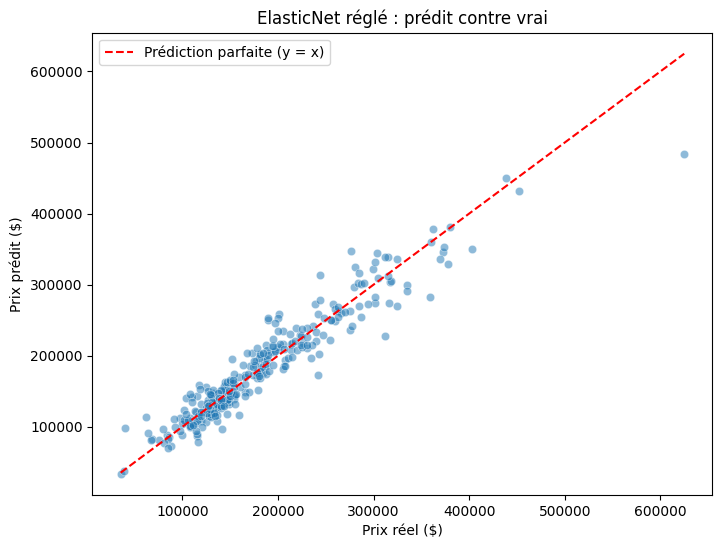

In [124]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=ygrid_test, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Prédiction parfaite (y = x)')
plt.xlabel("Prix réel ($)")
plt.ylabel("Prix prédit ($)")
plt.title("ElasticNet réglé : prédit contre vrai")
plt.legend()
plt.show()

In [ ]:
#Résidus contre valeur prédites

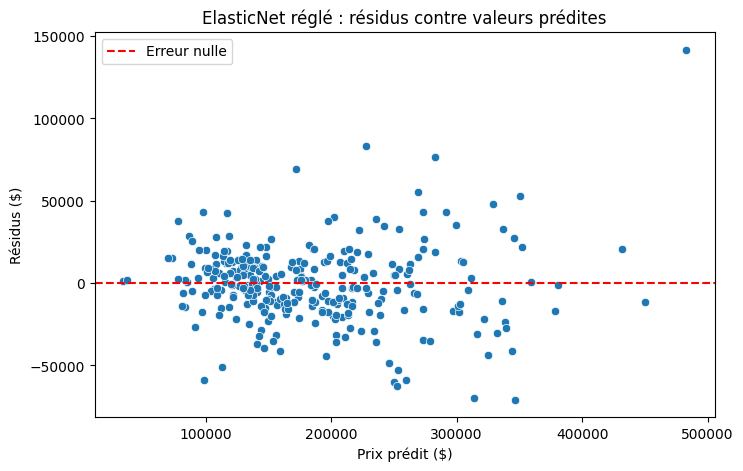

In [125]:
residus_grid = y_test - ygrid_test
plt.figure(figsize=(8, 5))
sns.scatterplot(x=ygrid_test, y=residus_grid)
plt.axhline(0, color='red', linestyle='--', label='Erreur nulle')
plt.xlabel("Prix prédit ($)")
plt.ylabel("Résidus ($)")
plt.title("ElasticNet réglé : résidus contre valeurs prédites")
plt.legend()
plt.show()

In [ ]:
#Les variables qui pésent le plus

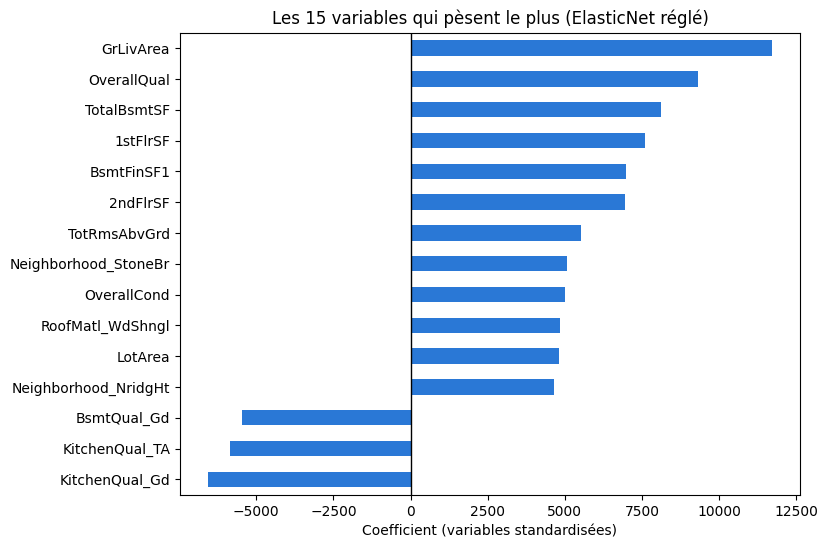

In [126]:
coefs = pd.Series(meilleur_estimation[-1].coef_, index=X_train.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(15).index).sort_values()
plt.figure(figsize=(8, 6))
top.plot(kind='barh', color='#2a78d6')
plt.axvline(0, color='black', linewidth=1)
plt.xlabel("Coefficient (variables standardisées)")
plt.title("Les 15 variables qui pèsent le plus (ElasticNet réglé)")
plt.show()

In [ ]:
#Comparaison des rmse_modeles

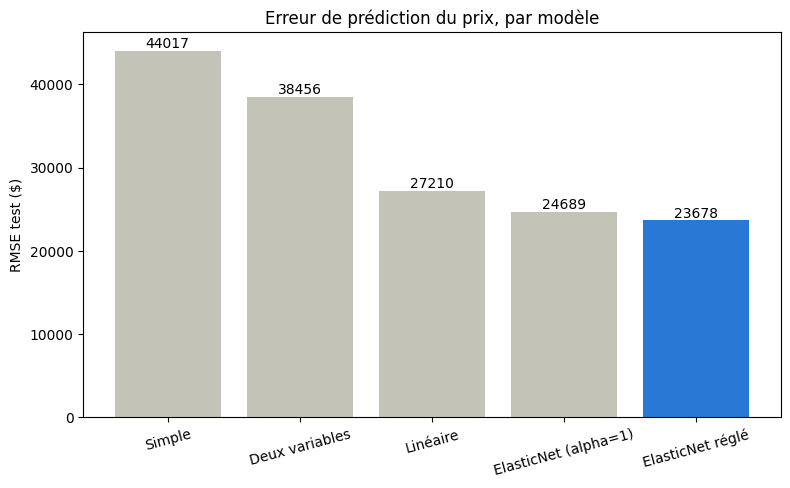

In [127]:
rmse_modeles = {
    'Simple': RMSE_simple,
    'Deux variables': RMSE_deux,
    'Linéaire': np.sqrt(mean_squared_error(y_test, y_pred_OLS)),
    'ElasticNet (alpha=1)': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))),
    'ElasticNet réglé': RMSEGridTest
}
plt.figure(figsize=(9, 5))
barres = plt.bar(rmse_modeles.keys(), rmse_modeles.values(), color=['#c4c3b8']*4 + ['#2a78d6'])
plt.bar_label(barres, fmt='%.0f')
plt.ylabel("RMSE test ($)")
plt.title("Erreur de prédiction du prix, par modèle")
plt.xticks(rotation=15)
plt.show()